# 📡 정보통신개론 개별 과제 제출 양식
## 내 목소리로 실습하는 AM · FM 변조와 PCM 부호화

| 항목 | 내용 |
|---|---|
| 제출물 | 이 노트북(실행 결과가 모두 남아 있는 상태) — `.ipynb` 파일 또는 Colab 공유 링크 |
| 파일 이름 | `정보통신개론_번호_이름.ipynb` |
| 진행 방법 | **설계(값 선택·기술) → 코드 작성 → 실행 결과 확인 → 결과 기록** 순서로 각 단계를 작성 |

### 작성 방법
1. **파일 → 드라이브에 사본 저장** 후 작업합니다.
2. 📝 표시 칸(마크다운 셀)은 **더블클릭**하여 `(작성)` 부분을 채웁니다.
3. 💻 표시 칸(코드 셀)에는 **직접 코드를 작성**하고 실행합니다. 셀 맨 위 주석의 **"반드시 나와야 할 것"** 이 출력되어야 합니다.
4. **변조·부호화 코드를 작성하기 전에 반드시 설계표(사용할 주파수, 변조지수 등)를 먼저 작성**합니다.
5. 모든 그래프 제목에는 **본인 번호와 이름**이 들어가도록 합니다.
6. 제출 전 **런타임 → 모두 실행**으로 오류 없이 결과가 나오는지 확인합니다.

## 1. 제출자 정보 📝

| 항목 | 내용 |
|---|---|
| 번호 | 03 |
| 이름 | 권신협 |
| 제출일 | 2026년 10월 22일 |

---
## 2. 본인 음성 신호 입력

In [ ]:
# ===== 2-2. 라이브러리 불러오기 · 기본 설정 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 사용할 라이브러리 import
#   2) 그래프 한글 글꼴 설정 (한글이 깨지지 않을 것)
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
import os, sys, glob, subprocess, base64
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fman
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, Javascript, display

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# 한글 폰트 설치 및 등록
if IN_COLAB and not glob.glob("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"):
    subprocess.run("apt-get -qq -y install fonts-nanum > /dev/null", shell=True)
font_files = (glob.glob("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
              + glob.glob("/usr/share/fonts/**/NotoSansCJK*-Regular.ttc", recursive=True))
if font_files:
    fman.fontManager.addfont(font_files[0])
    plt.rc("font", family=fman.FontProperties(fname=font_files[0]).get_name())

# 그래프 기본 스타일 (흑백 위주)
plt.rcParams.update({
    "axes.unicode_minus": False, "figure.figsize": (10, 3.2), "figure.dpi": 100,
    "axes.grid": True, "grid.color": "#dddddd", "axes.prop_cycle": plt.cycler(color=["black", "gray", "darkgray"]),
})

def play(x, fs, label=""):
    """소리 재생 플레이어 표시"""
    print(f"[소리 재생] {label}")
    display(Audio(np.asarray(x, dtype=float), rate=int(fs)))

def spectrum(x, fs):
    """주파수 스펙트럼 (최대값 기준 dB)"""
    X = np.abs(np.fft.rfft(x * np.hanning(len(x)))) + 1e-12
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, 20 * np.log10(X / X.max())

def spectrum_psd(sig, fs, nperseg=4096):
    """웰치 방법 전력 스펙트럼 → (주파수, dB, 전력)"""
    f, p = signal.welch(sig, fs=fs, nperseg=nperseg)
    return f, 10 * np.log10(p + 1e-20), p

def occupied_bw(f, p, ratio=0.99):
    """전체 전력의 ratio 가 들어 있는 주파수 구간 [f_lo, f_hi]"""
    cum = np.cumsum(p) / np.sum(p)
    return f[cum >= (1 - ratio) / 2][0], f[cum >= 1 - (1 - ratio) / 2][0]

def band_above(f, p_db, drop_db=60):
    """최대값보다 drop_db 이내인 주파수 구간 [f_lo, f_hi]"""
    sel = f[p_db > p_db.max() - drop_db]
    return sel.min(), sel.max()

print("환경 설정 완료 / Colab 환경:", IN_COLAB)

환경 설정 완료 / Colab 환경: True


In [ ]:
# ===== 2-3. 음성 신호 입력 모듈 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 본인 음성을 녹음(또는 업로드)하여 배열로 불러오기
#   2) 샘플링 주파수, 표본 수, 녹음 길이(초) 출력
#   3) 녹음한 음성을 재생할 수 있는 플레이어 (IPython.display.Audio)
#
# [참고]
#   - 녹음: google.colab.output + JavaScript MediaRecorder / 업로드: google.colab.files.upload()
#   - 변환·읽기: ffmpeg, scipy.io.wavfile, librosa 등 자유
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
SOURCE = "upload"      # "upload" | "record" | "sample"
RECORD_SEC = 4         # 녹음 시간(초)
FS_ANALOG = 44100      # '아날로그'로 간주할 고해상도 샘플링 주파수(Hz)
MAX_SEC = 4            # 실습에 사용할 최대 길이(초)

def to_wav(src, dst="voice_44k.wav"):
    """어떤 음성 파일이든 모노 44.1 kHz wav 로 변환해 읽기"""
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src,
                    "-ac", "1", "-ar", str(FS_ANALOG), dst], check=True)
    _, data = wavfile.read(dst)
    return data

RECORD_JS = """
const sleep = t => new Promise(r => setTimeout(r, t));
const toB64 = blob => new Promise(res => { const rd = new FileReader();
  rd.onloadend = () => res(rd.result); rd.readAsDataURL(blob); });
var record = async (sec) => {
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); await sleep(sec * 1000); rec.stop();
  await new Promise(r => rec.onstop = r);
  stream.getTracks().forEach(t => t.stop());
  return await toB64(new Blob(chunks));
}
"""

def record(sec):
    """Colab 브라우저 마이크로 녹음"""
    from google.colab.output import eval_js
    display(Javascript(RECORD_JS))
    print(f"{sec}초 동안 녹음합니다. 지금 말씀하세요...")
    data = eval_js(f"record({sec})")
    with open("rec.webm", "wb") as f:
        f.write(base64.b64decode(data.split(",")[1]))
    print("녹음 완료")
    return to_wav("rec.webm")

def sample_voice(sec=3.0, fs=FS_ANALOG):
    """합성 모음 음성 '아-에-이-오-우' (성대 펄스 + 포먼트 공명)"""
    t = np.arange(int(sec * fs)) / fs
    f0 = 140 + 20 * np.sin(2 * np.pi * 0.6 * t) + 4 * np.sin(2 * np.pi * 5.5 * t)   # 음높이 + 떨림
    pulses = np.diff(np.floor(np.cumsum(f0) / fs), prepend=0)                      # 성대 진동 펄스
    src = signal.lfilter([1], [1, -0.95], pulses)
    vowels = [(800, 1200, 2500), (500, 1900, 2500), (300, 2300, 3000), (500, 900, 2400), (330, 800, 2300)]
    seg = len(t) // len(vowels)
    out = []
    for k, formants in enumerate(vowels):
        y = src[k * seg:(k + 1) * seg]
        for F in formants:                                   # 포먼트(공명 주파수) 필터
            r = np.exp(-np.pi * 90 / fs)
            y = signal.lfilter([1 - r], [1, -2 * r * np.cos(2 * np.pi * F / fs), r * r], y)
        env = np.sin(np.linspace(0, np.pi, len(y))) ** 0.6   # 음절 크기 변화
        out.append(y * env)
    return np.concatenate(out)

# ── 음성 불러오기 ──
x = None
if SOURCE == "upload" and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        x = to_wav(next(iter(uploaded)))
    else:
        print("업로드된 파일이 없어 합성 예제 음성을 사용합니다.")
elif SOURCE == "record" and IN_COLAB:
    x = record(RECORD_SEC)
elif SOURCE != "sample":
    print("Colab 환경이 아니어서 합성 예제 음성을 사용합니다.")
if x is None:
    x = sample_voice()

# ── 정리: 모노, 정규화, 앞 무음 제거, 길이 제한 ──
x = np.asarray(x, dtype=float)
if x.ndim > 1:
    x = x.mean(axis=1)
x = x / (np.abs(x).max() + 1e-12)
start = int(np.argmax(np.abs(x) > 0.05))
x = x[start:start + MAX_SEC * FS_ANALOG]
x = 0.95 * x / np.abs(x).max()
t = np.arange(len(x)) / FS_ANALOG

# 확대해서 볼 10 ms 구간(소리가 가장 큰 곳) 자동 선택
ZOOM = int(0.010 * FS_ANALOG)
z0 = int(np.argmax(np.convolve(x ** 2, np.ones(ZOOM), "valid")))
z1 = z0 + ZOOM

print(f"샘플링 주파수 FS_ANALOG = {FS_ANALOG:,} Hz")
print(f"길이 {len(x) / FS_ANALOG:.2f}초, 표본 {len(x):,}개")
play(x, FS_ANALOG, "원본 음성")

샘플링 주파수 FS_ANALOG = 44,100 Hz
길이 3.84초, 표본 169,156개
[소리 재생] 원본 음성


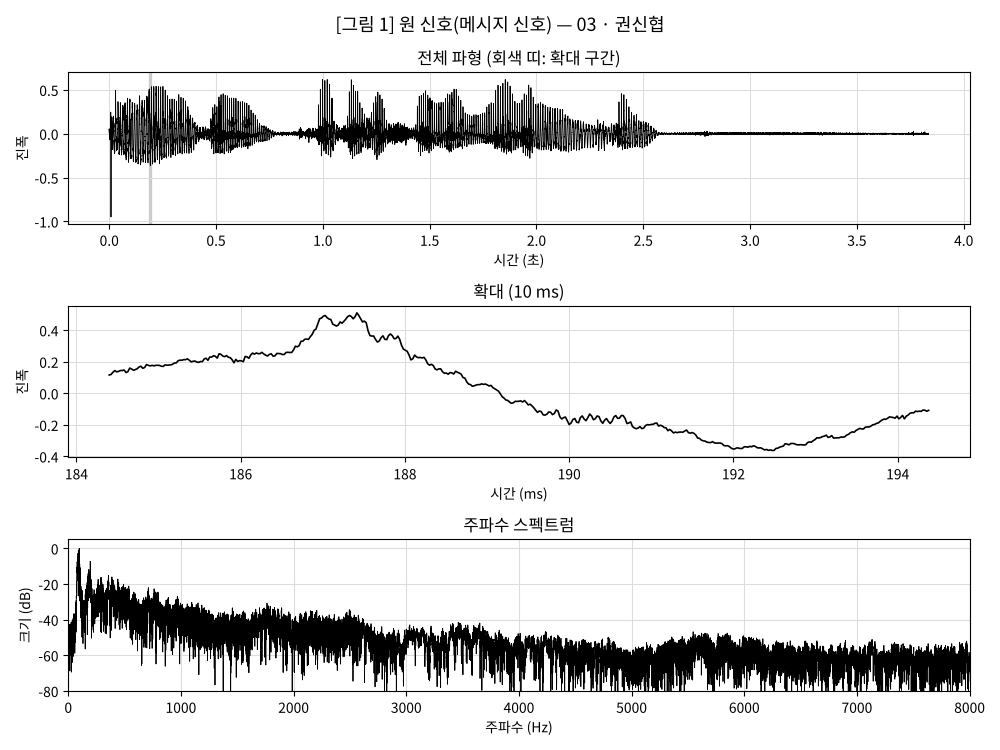

In [ ]:
# ===== 2-4. [그림 1] 원 신호(메시지 신호) 그래프 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 녹음한 음성 전체 파형 (가로축: 시간 [s])
#   2) 일부 구간(수십 ms) 확대 파형
#   3) 주파수 스펙트럼 (가로축: 주파수 [Hz])
#   4) 그래프 제목에 '[그림 1]'과 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
fig, ax = plt.subplots(3, 1, figsize=(10, 7.5))
fig.suptitle("[그림 1] 원 신호(메시지 신호) — 03 · 권신협", fontsize=13)

ax[0].plot(t, x, lw=0.6)
ax[0].axvspan(t[z0], t[z1], color="gray", alpha=0.3)
ax[0].set(title="전체 파형 (회색 띠: 확대 구간)", xlabel="시간 (초)", ylabel="진폭")

ax[1].plot(t[z0:z1] * 1000, x[z0:z1], lw=1.2)
ax[1].set(title="확대 (10 ms)", xlabel="시간 (ms)", ylabel="진폭")

f, X = spectrum(x, FS_ANALOG)
ax[2].plot(f, X, lw=0.6)
ax[2].set(title="주파수 스펙트럼", xlabel="주파수 (Hz)", ylabel="크기 (dB)",
          xlim=(0, 8000), ylim=(-80, 5))
plt.tight_layout()
plt.show()

---
## 3. AM 변조

$$s_{AM}(t) = A_c\,[\,1 + m\cdot x(t)\,]\cos(2\pi f_c t)$$

### 3-1. AM 변조 설계 📝

| 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---|---|---|
| 반송파 주파수 | fc | 10000 | Hz | 스피커로 들을 수 있도록 가청 대역의 주파수를 사용했습니다. 음성 대역 상한(3400 Hz)보다 충분히 높아 측파대가 0 Hz 아래로 내려가지 않습니다. |
| 반송파 진폭 | Ac | 1.0 | V | 기준이 되는 크기로 1.0 V를 사용했습니다. 포락선 최대·최소값을 계산하기 쉽습니다. |
| 변조지수 | m | 0.8 | - | 0 < m ≤ 1이면 정상 변조입니다. 0.8은 포락선이 음성 모양대로 크게 변하면서 과변조도 피하는 값입니다. |
| 메시지 최고 주파수 | fm | 3400 | Hz | 음성을 전화 품질 대역(300 ~ 3400 Hz)으로 제한했으므로 메시지의 최고 주파수는 3400 Hz입니다. |
| 변조에 사용할 샘플링 주파수 | Fs | 48000 | Hz | fc + fm = 10000 + 3400 = 13400 Hz가 Fs/2 = 24000 Hz보다 작아 조건을 만족합니다. ※ fc + fm < Fs/2 확인 |


In [ ]:
# ===== 3-2. AM 변조 파라미터 선언 (3-1 설계표의 값과 같아야 함) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 fc, Ac, m, fm, Fs 를 변수로 선언하고 print 로 출력
# ------------------------------------------------------------

FC = 10000   # 반송파 주파수 [Hz]
Ac = 1.0   # 반송파 진폭
M  = 0.8   # 변조지수
fm = 3400   # 메시지 최고 주파수 [Hz]
FS = 48000   # 변조용 샘플링 주파수 [Hz]

F_LOW  = 300     # 음성 대역 하한 [Hz]
F_HIGH = 3400    # 음성 대역 상한 [Hz] (전화 품질)
SNR_DB = 30      # 채널 잡음 (신호대잡음비, dB) — 작게 하면 잡음 증가

# 여기에 출력 코드를 작성하세요
print(f"FC : {FC} Hz")
print(f"Ac : {Ac} V")
print(f"M  : {M}")
print(f"fm : {fm} Hz")
print(f"FS : {FS} Hz")
print(f"음성 대역: {F_LOW} ~ {F_HIGH} Hz, 채널 SNR: {SNR_DB} dB")
print(f"fc + fm = {FC + fm} Hz  <  FS/2 = {FS // 2} Hz  →  {'조건 만족' if FC + fm < FS / 2 else '조건 불만족'}")
print(f"fc − fm = {FC - fm} Hz  >  0 Hz  →  {'조건 만족' if FC - fm > 0 else '조건 불만족'}")
print(f"변조지수 M = {M}  →  {'정상 변조 (0 < m ≤ 1)' if 0 < M <= 1 else '과변조'}")

FC : 10000 Hz
Ac : 1.0 V
M  : 0.8
fm : 3400 Hz
FS : 48000 Hz
음성 대역: 300 ~ 3400 Hz, 채널 SNR: 30 dB
fc + fm = 13400 Hz  <  FS/2 = 24000 Hz  →  조건 만족
fc − fm = 6600 Hz  >  0 Hz  →  조건 만족
변조지수 M = 0.8  →  정상 변조 (0 < m ≤ 1)


In [ ]:
# ===== 3-3. AM 변조 구현 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 음성 신호를 정규화(|x(t)| ≤ 1)하고 필요하면 Fs 로 업샘플링
#   2) 반송파 c(t) 와 AM 신호 s(t) 생성
#   3) 포락선 최대·최소값, 측정 변조지수 (Amax−Amin)/(Amax+Amin) 출력
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
# ① 44,100 Hz 음성을 변조용 FS(48,000 Hz)로 바꾸기 (정수비 160/147 로 업샘플링)
g = int(np.gcd(FS, FS_ANALOG))
x_mod = signal.resample_poly(x, FS // g, FS_ANALOG // g)

# ② 음성 대역(300~3400 Hz)만 남기고 |x(t)| ≤ 1 로 정규화 → 신호파 x(t)
sos_bp = signal.butter(6, [F_LOW, F_HIGH], btype="band", fs=FS, output="sos")
msg = signal.sosfiltfilt(sos_bp, x_mod)
msg = msg / (np.max(np.abs(msg)) + 1e-12)
t_mod = np.arange(len(msg)) / FS                       # 변조용 시간축 [s]

# 확대해서 볼 20 ms 구간 (신호파 에너지가 가장 큰 곳)
W_MOD = int(0.020 * FS)
s0 = int(np.argmax(np.convolve(msg ** 2, np.ones(W_MOD), "valid")))

# ③ 반송파 c(t) 와 AM 신호 s(t) = [1 + m·x(t)]·c(t)
carrier = Ac * np.cos(2 * np.pi * FC * t_mod)
envelope = Ac * (1 + M * msg)                          # 이론 포락선
am = (1 + M * msg) * carrier

# ④ 포락선 측정 (힐베르트 변환으로 파형에서 직접 구함, 변환 오차가 생기는 양 끝 2 ms 제외)
edge = int(0.002 * FS)
env_meas = np.abs(signal.hilbert(am))[edge:-edge]
A_max, A_min = env_meas.max(), env_meas.min()
m_meas = (A_max - A_min) / (A_max + A_min)

print(f"신호파: {len(msg):,}개 표본 ({len(msg) / FS:.2f}초), 최대 {msg.max():+.3f}, 최소 {msg.min():+.3f}")
print(f"이론 포락선: 최대 {envelope.max():.3f}, 최소 {envelope.min():.3f}")
print(f"측정 포락선: 최대 {A_max:.3f}, 최소 {A_min:.3f}")
print(f"측정 변조지수 (Amax−Amin)/(Amax+Amin) = {m_meas:.3f}  (설계값 M = {M})")
print(f"이론 변조지수 = {(envelope.max() - envelope.min()) / (envelope.max() + envelope.min()):.3f}")
print(f"과변조 여부: {'과변조 (1 + m·x 가 음수)' if envelope.min() < 0 else '과변조 아님 (포락선 최소값이 0보다 큼)'}")

신호파: 184,116개 표본 (3.84초), 최대 +0.657, 최소 -1.000
이론 포락선: 최대 1.526, 최소 0.200
측정 포락선: 최대 1.526, 최소 0.200
측정 변조지수 (Amax−Amin)/(Amax+Amin) = 0.768  (설계값 M = 0.8)
이론 변조지수 = 0.768
과변조 여부: 과변조 아님 (포락선 최소값이 0보다 큼)


스펙트럼 관찰 (최대값 −60 dB 이내): 7,500 ~ 12,504 Hz → 대역폭 약 5,004 Hz
하측파대 LSB: 7,500 ~ 10,000 Hz,  상측파대 USB: 10,000 ~ 12,504 Hz


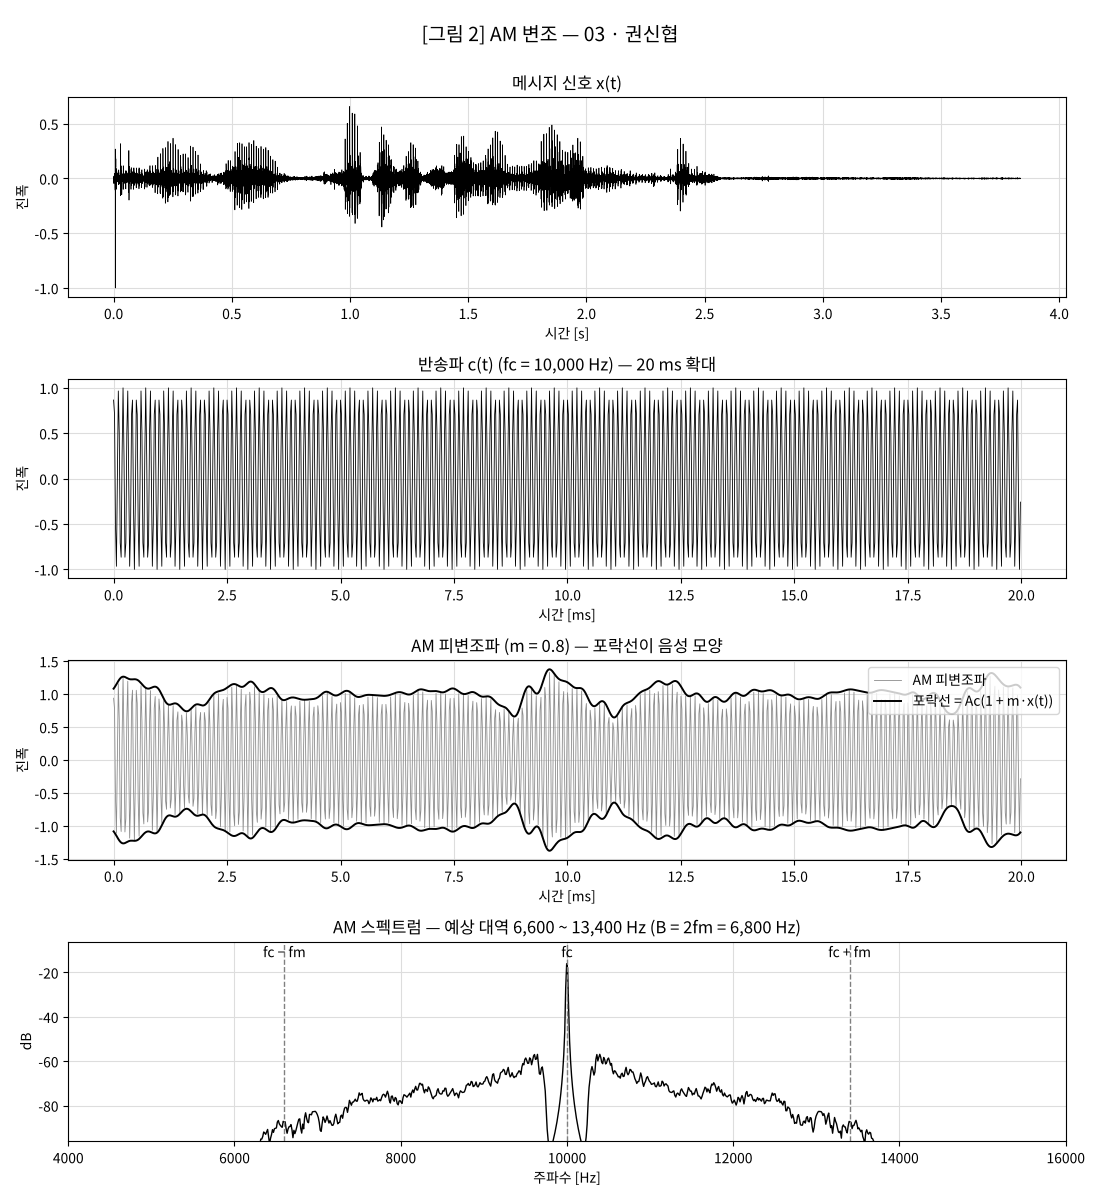

In [ ]:
# ===== 3-4. [그림 2] AM 변조 그래프 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 메시지 신호 x(t)
#   2) 반송파 c(t) (확대)
#   3) AM 변조 파형 + 포락선
#   4) AM 스펙트럼 (fc, fc±fm 위치 표시)
#   5) 그래프 제목에 '[그림 2]'와 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
fig, ax = plt.subplots(4, 1, figsize=(11, 12))
fig.suptitle("[그림 2] AM 변조 — 03 · 권신협", fontsize=14)
sl = slice(s0, s0 + W_MOD)
tz = (t_mod[sl] - t_mod[s0]) * 1000

ax[0].plot(t_mod, msg, "k", lw=0.5)
ax[0].set(title="메시지 신호 x(t)", xlabel="시간 [s]", ylabel="진폭")

ax[1].plot(tz, carrier[sl], "k", lw=0.6)
ax[1].set(title=f"반송파 c(t) (fc = {FC:,} Hz) — 20 ms 확대", xlabel="시간 [ms]", ylabel="진폭")

ax[2].plot(tz, am[sl], color="0.55", lw=0.6, label="AM 피변조파")
ax[2].plot(tz, envelope[sl], "k", lw=1.4, label="포락선 = Ac(1 + m·x(t))")
ax[2].plot(tz, -envelope[sl], "k", lw=1.4)
ax[2].set(title=f"AM 피변조파 (m = {M}) — 포락선이 음성 모양", xlabel="시간 [ms]", ylabel="진폭")
ax[2].legend(loc="upper right")

f, Pa_db, Pa = spectrum_psd(am, FS)
ax[3].plot(f, Pa_db, "k", lw=1)
for fx in (FC - fm, FC, FC + fm):
    ax[3].axvline(fx, color="0.5", ls="--", lw=1)
ax[3].text(FC, Pa_db.max() + 3, "fc", ha="center")
ax[3].text(FC - fm, Pa_db.max() + 3, "fc − fm", ha="center")
ax[3].text(FC + fm, Pa_db.max() + 3, "fc + fm", ha="center")
ax[3].set(title=f"AM 스펙트럼 — 예상 대역 {FC - fm:,} ~ {FC + fm:,} Hz (B = 2fm = {2 * fm:,} Hz)",
          xlabel="주파수 [Hz]", ylabel="dB", xlim=(FC - 6000, FC + 6000), ylim=(Pa_db.max() - 80, Pa_db.max() + 10))
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

lo, hi = band_above(f, Pa_db, 60)
print(f"스펙트럼 관찰 (최대값 −60 dB 이내): {lo:,.0f} ~ {hi:,.0f} Hz → 대역폭 약 {hi - lo:,.0f} Hz")
print(f"하측파대 LSB: {lo:,.0f} ~ {FC:,} Hz,  상측파대 USB: {FC:,} ~ {hi:,.0f} Hz")

### 3-5. AM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| 변조지수 m | 0.8 | 측정: 0.768 (포락선 최대 1.526, 최소 0.200) | 약간 낮습니다. 정규화한 음성의 최대가 +0.657, 최소가 −1.000으로 비대칭입니다. 이 값으로 계산한 이론값은 0.768이고 측정값과 같습니다. 두 값이 같으므로 변조는 정상입니다. |
| 대역폭 B | 2fm = 6,800 Hz | 스펙트럼 관찰: 약 5,004 Hz | 관찰값이 좁습니다. 음성 에너지는 낮은 주파수에 몰려 있어 3400 Hz 근처 성분은 최대값보다 60 dB 넘게 작습니다. 필터를 통과한 대역 자체는 3-3에서 300 ~ 3400 Hz입니다. |
| 측파대 범위 | LSB 6,600 ~ 10,000 Hz / USB 10,000 ~ 13,400 Hz | LSB 7,500 ~ 10,000 Hz / USB 10,000 ~ 12,504 Hz | 관찰 범위가 예상 범위 안에 들어 있습니다. 바깥쪽 끝은 위와 같은 이유로 최대값 −60 dB 아래로 내려갑니다. |
| 과변조 여부 | 과변조 아님 (m = 0.8 ≤ 1) | 과변조 아님 (포락선 최소값 0.200 > 0) | 일치합니다. 1 + m·x(t)가 항상 양수여서 포락선이 뒤집히지 않았습니다. |


---
## 4. FM 변조

$$s_{FM}(t) = A_c\cos\!\Big(2\pi f_c t + 2\pi\,\Delta f\!\int_0^t x(\tau)\,d\tau\Big),\qquad f_i(t)=f_c+\Delta f\cdot x(t)$$

### 4-1. FM 변조 설계 📝 (⚠️ 코드를 작성하기 전에 먼저 작성)

| 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---|---|---|
| 반송파 주파수 | fc | 10000 | Hz | AM과 같은 값으로 두 방식을 같은 조건에서 비교하기 위해서입니다. 귀로 들을 수 있는 '삐' 소리의 높이입니다. |
| 반송파 진폭 | Ac | 1.0 | V | FM은 진폭이 항상 일정해야 하므로 AM과 같은 1.0 V로 고정했습니다. |
| 최대 주파수 편이 | Δf | 3000 | Hz | 음성이 가장 클 때 반송파가 벗어나는 폭입니다. 순시 주파수는 7000 ~ 13000 Hz가 되고 Carson 대역의 아래쪽 끝(3600 Hz)도 0 Hz보다 높습니다. |
| 메시지 최고 주파수 | fm | 3400 | Hz | 음성을 300 ~ 3400 Hz로 제한했으므로 메시지의 최고 주파수는 3400 Hz입니다. |
| 변조에 사용할 샘플링 주파수 | Fs | 48000 | Hz | AM과 같은 값입니다. fc + Δf + fm = 10000 + 3000 + 3400 = 16400 Hz가 Fs/2 = 24000 Hz보다 작아 조건을 만족합니다. ※ fc + Δf + fm < Fs/2 확인 |


In [ ]:
# ===== 4-2. FM 변조 파라미터 선언 (4-1 설계표의 값과 같아야 함) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 fc, Ac, Δf, fm, Fs 를 변수로 선언하고 print 로 출력
# ------------------------------------------------------------

fc_fm = 10000   # 반송파 주파수 [Hz]
Ac_fm = 1.0   # 반송파 진폭
df    = 3000   # 최대 주파수 편이 Δf [Hz]
fm    = 3400   # 메시지 최고 주파수 [Hz]
Fs    = 48000   # 변조용 샘플링 주파수 [Hz]

# 여기에 출력 코드를 작성하세요
print(f"fc_fm: {fc_fm} Hz")
print(f"Ac_fm: {Ac_fm} V")
print(f"df   : {df} Hz")
print(f"fm   : {fm} Hz")
print(f"Fs   : {Fs} Hz")
print(f"fc + Δf + fm = {fc_fm + df + fm} Hz  <  Fs/2 = {Fs // 2} Hz  →  {'조건 만족' if fc_fm + df + fm < Fs / 2 else '조건 불만족'}")
print(f"fc − Δf − fm = {fc_fm - df - fm} Hz  >  0 Hz  →  {'조건 만족' if fc_fm - df - fm > 0 else '조건 불만족'}")
assert Fs == FS, "신호파 msg 는 FS(3-2)로 만들어졌으므로 Fs 와 같아야 합니다"

fc_fm: 10000 Hz
Ac_fm: 1.0 V
df   : 3000 Hz
fm   : 3400 Hz
Fs   : 48000 Hz
fc + Δf + fm = 16400 Hz  <  Fs/2 = 24000 Hz  →  조건 만족
fc − Δf − fm = 3600 Hz  >  0 Hz  →  조건 만족


In [ ]:
# ===== 4-3. FM 변조 구현 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 메시지 신호의 적분(누적합)으로 위상 생성
#   2) FM 신호 s(t) 생성
#   3) 순시 주파수 fi(t) 계산, 최대·최소 순시 주파수 출력
#   4) β, Carson 대역폭 출력
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
dt = 1 / Fs                                              # 샘플 사이 시간 간격 [s]
integral_msg = np.cumsum(msg) * dt                       # ① 신호파 적분 (누적합)
phase = 2 * np.pi * fc_fm * t_mod + 2 * np.pi * df * integral_msg   # ② 위상
fm_sig = Ac_fm * np.cos(phase)                           # ③ FM 신호 s(t)

inst_freq_tx = fc_fm + df * msg                          # 순시 주파수 fi(t) = fc + Δf·x(t)
inst_freq_ph = np.append(np.diff(phase) * Fs / (2 * np.pi), np.nan)   # 위상 미분으로 잰 값 (확인용)

beta = df / fm                                           # 변조지수 β = Δf / fm
B_carson = 2 * (df + fm)                                 # Carson 대역폭

print(f"FM 신호: {len(fm_sig):,}개 표본, 진폭 범위 {fm_sig.min():.3f} ~ {fm_sig.max():.3f}")
print(f"최대 순시 주파수: {inst_freq_tx.max():,.1f} Hz (fc + Δf·x_max, 이론 상한 {fc_fm + df:,} Hz)")
print(f"최소 순시 주파수: {inst_freq_tx.min():,.1f} Hz (fc + Δf·x_min, 이론 하한 {fc_fm - df:,} Hz)")
print(f"위상 미분으로 잰 값과 fi(t) 의 최대 차이: {np.nanmax(np.abs(inst_freq_ph[:-1] - inst_freq_tx[1:])):.6f} Hz")
print(f"β = Δf / fm = {df} / {fm} = {beta:.2f}")
print(f"Carson 대역폭 B = 2(Δf + fm) = {B_carson:,} Hz  ({fc_fm - B_carson // 2:,} ~ {fc_fm + B_carson // 2:,} Hz)")

FM 신호: 184,116개 표본, 진폭 범위 -1.000 ~ 1.000
최대 순시 주파수: 11,971.2 Hz (fc + Δf·x_max, 이론 상한 13,000 Hz)
최소 순시 주파수: 7,000.0 Hz (fc + Δf·x_min, 이론 하한 7,000 Hz)
위상 미분으로 잰 값과 fi(t) 의 최대 차이: 0.000001 Hz
β = Δf / fm = 3000 / 3400 = 0.88
Carson 대역폭 B = 2(Δf + fm) = 12,800 Hz  (3,600 ~ 16,400 Hz)


스펙트럼 관찰 (전력 99 %): 9,305 ~ 10,793 Hz → 대역폭 약 1,488 Hz
스펙트럼 관찰 (최대값 −60 dB 이내): 7,336 ~ 12,891 Hz → 대역폭 약 5,555 Hz
Carson 대역폭(이론): 12,800 Hz


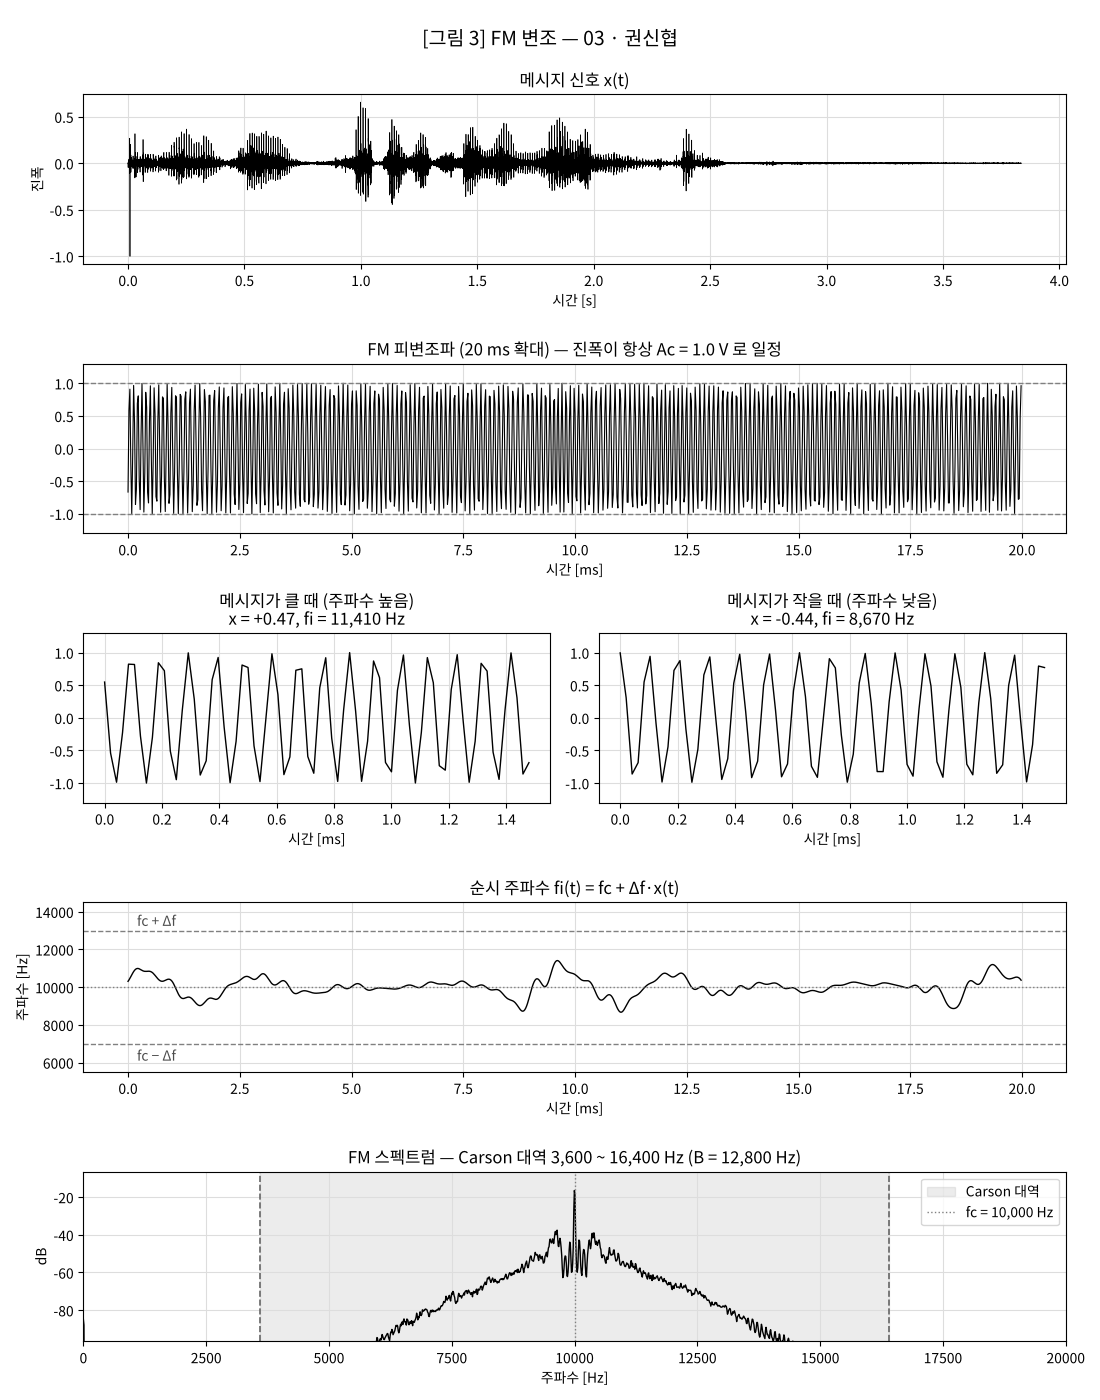

In [ ]:
# ===== 4-4. [그림 3] FM 변조 그래프 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 메시지 신호 x(t)
#   2) FM 변조 파형 (진폭 일정 확인)
#   3) 메시지가 클 때 / 작을 때의 FM 파형 확대 비교
#   4) 순시 주파수 fi(t)
#   5) FM 스펙트럼 (Carson 대역 표시)
#   6) 그래프 제목에 '[그림 3]'과 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
fig = plt.figure(figsize=(11, 14))
gs = fig.add_gridspec(5, 2)
fig.suptitle("[그림 3] FM 변조 — 03 · 권신협", fontsize=14)
sl = slice(s0, s0 + W_MOD)
tz = (t_mod[sl] - t_mod[s0]) * 1000

ax = fig.add_subplot(gs[0, :])
ax.plot(t_mod, msg, "k", lw=0.5)
ax.set(title="메시지 신호 x(t)", xlabel="시간 [s]", ylabel="진폭")

ax = fig.add_subplot(gs[1, :])
ax.plot(tz, fm_sig[sl], "k", lw=0.8)
ax.axhline(Ac_fm, color="0.5", ls="--", lw=1); ax.axhline(-Ac_fm, color="0.5", ls="--", lw=1)
ax.set(title=f"FM 피변조파 (20 ms 확대) — 진폭이 항상 Ac = {Ac_fm} V 로 일정", xlabel="시간 [ms]", ylim=(-1.3, 1.3))

# 메시지가 클 때 / 작을 때 (1.5 ms 확대, 에너지가 큰 구간 안에서 선택)
WZ = int(0.0015 * Fs)
i_hi = s0 + int(np.argmax(msg[sl]))
i_lo = s0 + int(np.argmin(msg[sl]))
for col, i_c, name in [(0, i_hi, "메시지가 클 때 (주파수 높음)"), (1, i_lo, "메시지가 작을 때 (주파수 낮음)")]:
    a = min(max(0, i_c - WZ // 2), len(fm_sig) - WZ)
    ax = fig.add_subplot(gs[2, col])
    ax.plot((t_mod[a:a + WZ] - t_mod[a]) * 1000, fm_sig[a:a + WZ], "k", lw=1)
    ax.set(title=f"{name}\nx = {msg[i_c]:+.2f}, fi = {inst_freq_tx[i_c]:,.0f} Hz", xlabel="시간 [ms]", ylim=(-1.3, 1.3))

ax = fig.add_subplot(gs[3, :])
ax.plot(tz, inst_freq_tx[sl], "k", lw=1)
ax.axhline(fc_fm, color="0.5", ls=":", lw=1)
ax.axhline(fc_fm + df, color="0.5", ls="--", lw=1); ax.axhline(fc_fm - df, color="0.5", ls="--", lw=1)
ax.text(0.2, fc_fm + df + 250, "fc + Δf", color="0.3"); ax.text(0.2, fc_fm - df - 900, "fc − Δf", color="0.3")
ax.set(title="순시 주파수 fi(t) = fc + Δf·x(t)", xlabel="시간 [ms]", ylabel="주파수 [Hz]",
       ylim=(fc_fm - df - 1500, fc_fm + df + 1500))

f, fm_db, fm_p = spectrum_psd(fm_sig, Fs)
ax = fig.add_subplot(gs[4, :])
ax.plot(f, fm_db, "k", lw=1)
ax.axvspan(fc_fm - B_carson / 2, fc_fm + B_carson / 2, color="gray", alpha=0.15, label="Carson 대역")
for fx in (fc_fm - B_carson / 2, fc_fm + B_carson / 2):
    ax.axvline(fx, color="0.4", ls="--", lw=1.2)
ax.axvline(fc_fm, color="0.5", ls=":", lw=1, label=f"fc = {fc_fm:,} Hz")
ax.set(title=f"FM 스펙트럼 — Carson 대역 {fc_fm - B_carson // 2:,} ~ {fc_fm + B_carson // 2:,} Hz (B = {B_carson:,} Hz)",
       xlabel="주파수 [Hz]", ylabel="dB", xlim=(0, 20000), ylim=(fm_db.max() - 80, fm_db.max() + 10))
ax.legend(loc="upper right")
plt.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

f_lo, f_hi = occupied_bw(f, fm_p)
b_lo, b_hi = band_above(f, fm_db, 60)
print(f"스펙트럼 관찰 (전력 99 %): {f_lo:,.0f} ~ {f_hi:,.0f} Hz → 대역폭 약 {f_hi - f_lo:,.0f} Hz")
print(f"스펙트럼 관찰 (최대값 −60 dB 이내): {b_lo:,.0f} ~ {b_hi:,.0f} Hz → 대역폭 약 {b_hi - b_lo:,.0f} Hz")
print(f"Carson 대역폭(이론): {B_carson:,} Hz")

### 4-5. FM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| β | Δf / fm = 3000 / 3400 ≈ 0.88 | 0.88 | 일치합니다. β가 1보다 작아 협대역에 가까운 FM입니다. |
| Carson 대역폭 | 2(Δf + fm) = 12,800 Hz | 스펙트럼 관찰: 약 5,555 Hz (최대값 −60 dB 이내, 7,336 ~ 12,891 Hz) | 관찰값이 좁습니다. Carson 대역폭은 음성이 항상 최대 크기일 때를 기준으로 합니다. 실제 음성은 98 %의 구간에서 \|x\| < 0.2이고 실효값이 약 0.053이어서 평균 주파수 편이는 약 160 Hz였습니다. 전력 99 %는 약 1,488 Hz 안에 들어 있고, 스펙트럼 전체는 Carson 대역(3,600 ~ 16,400 Hz) 안에 있습니다. |
| 순시 주파수 범위 | 7,000 ~ 13,000 Hz | 7,000.0 ~ 11,971.2 Hz | 하한은 일치하고 상한은 낮습니다. 정규화한 음성의 최소가 −1.000, 최대가 +0.657이어서 최대 순시 주파수는 10000 + 3000 × 0.657 ≈ 11,971 Hz가 되었습니다. |
| 신호 진폭 | 일정 (Ac) | 최대 1.000, 최소 −1.000 | 일치합니다. 메시지 크기가 변해도 진폭은 Ac = 1.0 V로 일정하고 주파수만 변했습니다. |


## 5. PCM (표본화 → 양자화 → 부호화)

```
 아날로그 m(t) ──▶ [① 표본화 fs] ──▶ [② 양자화 n비트] ──▶ [③ 부호화] ──▶ 0110 1001 0111 …
```

### 5-1. PCM 설계 📝

| 단계 | 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---|---|---|---|
| 표본화 | 표본화 주파수 | fs | 8000 | Hz | 전화망(G.711)이 음성을 300 ~ 3,400 Hz로 제한하고 8,000 Hz로 표본화합니다. 8,000 ≥ 2 × 3,400이므로 나이퀴스트 조건을 만족합니다. ※ 나이퀴스트 조건 fs ≥ 2fm |
| 양자화 | 양자화 비트 수 | n | 8 | bit | 전화 음성(8 kHz × 8 bit)은 64 kbps입니다. 256단계로 음성을 표현하기에 충분한 비트 수입니다. |
| 양자화 | 양자화 방식 | - | ☑ 균일(선형) ☐ 비균일(μ-law 등) | - | 단계 간격이 일정해 이론 SQNR(6.02n + 1.76)과 측정값을 바로 비교할 수 있습니다. |
| 양자화 | 진폭 범위 | - | -1.0 ~ +1.0 | V | 음성을 \|x\| ≤ 1로 정규화한 신호를 그대로 사용하므로 같은 범위를 썼습니다. |
| 부호화 | 부호화 방식 | - | ☑ 자연 2진 ☐ 부호-크기 ☐ 2의 보수 ☐ 기타 | - | 단계 번호(0 ~ 255)를 그대로 2진수로 바꾸므로 표본값과 부호의 대응을 확인하기 쉽습니다. |
| 출력 | 일련 데이터 표시 범위 | - | 1 번째 표본부터 16 개 | - | 16개 × 8비트 = 128비트로 한 화면에서 확인하기 알맞은 길이입니다. |

**설계 단계 예상값 (계산)**

| 항목 | 계산식 | 예상값 | 단위 |
|---|---|---|---|
| 표본화 주기 | Ts = 1 / fs | 125 | μs |
| 나이퀴스트 율 | 2fm | 6800 | Hz |
| 양자화 레벨 수 | L = 2ⁿ | 256 | 개 |
| 양자화 간격 | Δ = (진폭 범위) / L | 2 / 256 = 0.0078125 | V |
| 이론 SQNR | 6.02n + 1.76 | 49.92 | dB |
| 비트율 | R = fs × n | 64,000 | bps |


In [ ]:
# ===== 5-2. PCM 파라미터 선언 (5-1 설계표의 값과 같아야 함) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 fs, n 등을 변수로 선언하고 print 로 출력
# ------------------------------------------------------------

fs_pcm = 8000   # 표본화 주파수 [Hz]
n_bits = 8   # 양자화 비트 수

# 여기에 출력 코드를 작성하세요
CUTOFF = 3400                 # 앨리어싱 방지 필터 차단 주파수 [Hz] (fs_pcm/2 보다 작아야 함)
V_MIN, V_MAX = -1.0, 1.0      # 양자화 진폭 범위 [V]
SHOW_START, SHOW_N = 1, 16    # 일련 데이터 표시 범위 (1번째 표본부터 16개)

L_pcm = 2 ** n_bits                 # 양자화 레벨 수
delta = (V_MAX - V_MIN) / L_pcm     # 양자화 간격

print(f"fs_pcm : {fs_pcm} Hz  (표본화 주기 Ts = {1e6 / fs_pcm:.0f} μs)")
print(f"n_bits : {n_bits} bit")
print(f"CUTOFF : {CUTOFF} Hz  (앨리어싱 방지 필터)")
print("양자화 방식: 균일(선형), 부호화 방식: 자연 2진")
print(f"진폭 범위: {V_MIN} ~ {V_MAX} V")
print(f"나이퀴스트 조건: fs = {fs_pcm} Hz ≥ 2·fm = {2 * fm} Hz  →  {'만족' if fs_pcm >= 2 * fm else '불만족'}")
print(f"필터 조건: CUTOFF = {CUTOFF} Hz < fs/2 = {fs_pcm // 2} Hz  →  {'만족' if CUTOFF < fs_pcm / 2 else '불만족'}")
print(f"레벨 수 L = {L_pcm}, 양자화 간격 Δ = {delta:.7f}")
print(f"이론 SQNR = {6.02 * n_bits + 1.76:.2f} dB, 비트율 R = {fs_pcm * n_bits:,} bps")
print(f"일련 데이터 표시 범위: {SHOW_START}번째 표본부터 {SHOW_N}개")

fs_pcm : 8000 Hz  (표본화 주기 Ts = 125 μs)
n_bits : 8 bit
CUTOFF : 3400 Hz  (앨리어싱 방지 필터)
양자화 방식: 균일(선형), 부호화 방식: 자연 2진
진폭 범위: -1.0 ~ 1.0 V
나이퀴스트 조건: fs = 8000 Hz ≥ 2·fm = 6800 Hz  →  만족
필터 조건: CUTOFF = 3400 Hz < fs/2 = 4000 Hz  →  만족
레벨 수 L = 256, 양자화 간격 Δ = 0.0078125
이론 SQNR = 49.92 dB, 비트율 R = 64,000 bps
일련 데이터 표시 범위: 1번째 표본부터 16개


표본화 주파수 8,000 Hz → 표본 간격 125 μs, 표본 수 30,686개
원 신호 표본 169,156개 → 30,686개 (5.5배 감소)
표본값 앞 8개: [0.0483 0.0498 0.039  0.0126 0.0059 0.0175 0.0258 0.0241]


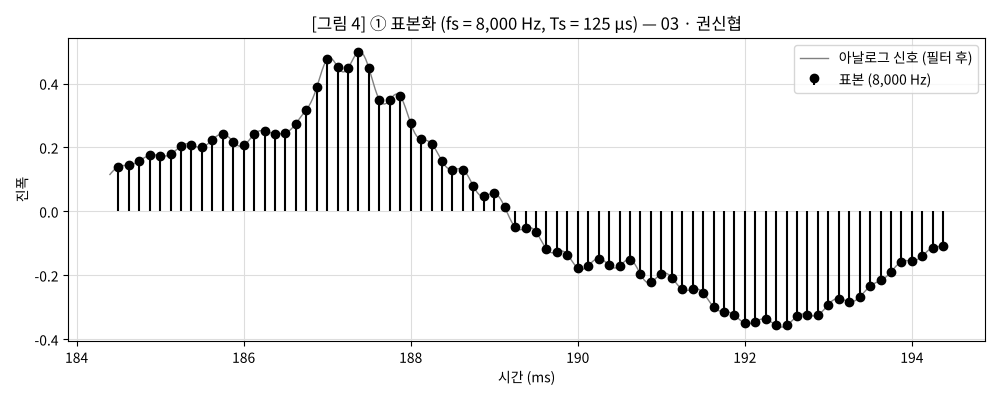

In [ ]:
# ===== 5-3. [그림 4] ① 표본화 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 음성 신호를 fs 로 표본화한 표본값 배열
#   2) 아날로그 신호 위에 표본점(stem)을 겹친 그래프 (수 ms 구간)
#   3) 표본 수 출력
#   4) 그래프 제목에 '[그림 4]'와 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
sos_aa = signal.butter(8, CUTOFF, fs=FS_ANALOG, output="sos")
x_f = signal.sosfiltfilt(sos_aa, x)                           # 1) 앨리어싱 방지 필터
t_s = np.arange(0, len(x) / FS_ANALOG, 1 / fs_pcm)            # 2) 1/fs 초 간격의 표본 시각
x_s = np.interp(t_s, t, x_f)                                  # 3) 그 시각의 값을 뽑음 → 표본값 배열

print(f"표본화 주파수 {fs_pcm:,} Hz → 표본 간격 {1e6 / fs_pcm:.0f} μs, 표본 수 {len(x_s):,}개")
print(f"원 신호 표본 {len(x):,}개 → {len(x_s):,}개 ({len(x) / len(x_s):.1f}배 감소)")
print("표본값 앞 8개:", np.round(x_s[:8], 4))

m = (t_s >= t[z0]) & (t_s < t[z1])                            # 확대 구간(10 ms)에 속한 표본

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t[z0:z1] * 1000, x_f[z0:z1], color="gray", lw=1, label="아날로그 신호 (필터 후)")
ax.stem(t_s[m] * 1000, x_s[m], linefmt="k-", markerfmt="ko", basefmt=" ", label=f"표본 ({fs_pcm:,} Hz)")
ax.set(title=f"[그림 4] ① 표본화 (fs = {fs_pcm:,} Hz, Ts = {1e6 / fs_pcm:.0f} μs) — 03 · 권신협",
       xlabel="시간 (ms)", ylabel="진폭")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

양자화 레벨 수 L = 256, 간격 Δ = 0.0078125
   표본 번호       표본값    레벨 번호      양자화 값
    1477    0.1393      145     0.1367
    1478    0.1449      146     0.1445
    1479    0.1582      148     0.1602
    1480    0.1752      150     0.1758
    1481    0.1745      150     0.1758
    1482    0.1785      150     0.1758
    1483    0.2050      154     0.2070
    1484    0.2087      154     0.2070
최대 양자화 오차 = 0.00391  (이론 최대 Δ/2 = 0.00391)
측정 SQNR: 8비트 32.88 dB / 3비트 0.69 dB
이론 SQNR (6.02n + 1.76): 8비트 49.92 dB


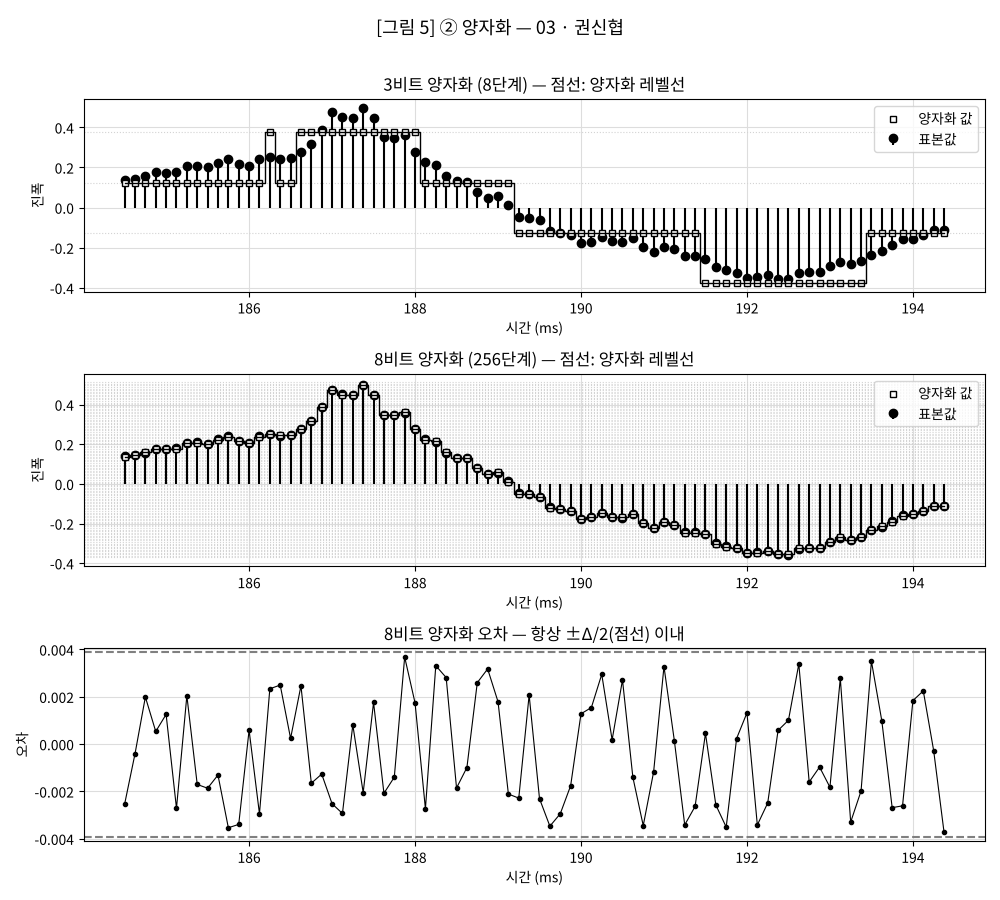

In [ ]:
# ===== 5-4. [그림 5] ② 양자화 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 표본값을 L 개 레벨로 양자화한 레벨 번호와 양자화 값
#   2) 표본값과 양자화 값(계단)을 겹친 그래프 + 양자화 레벨선
#   3) 양자화 오차 그래프
#   4) 측정 SQNR 출력
#   5) 그래프 제목에 '[그림 5]'와 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
def quantize(v, nb):
    """[V_MIN, V_MAX] 범위를 2^nb 단계로 균일 양자화 → (레벨 번호, 양자화 값)"""
    L = 2 ** nb
    d = (V_MAX - V_MIN) / L
    idx = np.clip(np.floor((v - V_MIN) / d), 0, L - 1).astype(int)
    return idx, V_MIN + (idx + 0.5) * d

def sqnr_db(ref, q):
    return 10 * np.log10(np.sum(ref ** 2) / np.sum((ref - q) ** 2))

q_idx, x_q = quantize(x_s, n_bits)                  # 설계한 n 비트
q_idx3, x_q3 = quantize(x_s, 3)                     # 비교용 3 비트
err = x_q - x_s
sqnr_meas = sqnr_db(x_s, x_q)
sqnr_theory = 6.02 * n_bits + 1.76

print(f"양자화 레벨 수 L = {L_pcm}, 간격 Δ = {delta:.7f}")
k0 = int(np.argmax(m))                              # 확대 구간의 첫 표본
print(f"{'표본 번호':>8} {'표본값':>9} {'레벨 번호':>8} {'양자화 값':>10}")
for k in range(k0, k0 + 8):
    print(f"{k + 1:>8} {x_s[k]:>9.4f} {q_idx[k]:>8d} {x_q[k]:>10.4f}")
print(f"최대 양자화 오차 = {np.abs(err).max():.5f}  (이론 최대 Δ/2 = {delta / 2:.5f})")
print(f"측정 SQNR: {n_bits}비트 {sqnr_meas:.2f} dB / 3비트 {sqnr_db(x_s, x_q3):.2f} dB")
print(f"이론 SQNR (6.02n + 1.76): {n_bits}비트 {sqnr_theory:.2f} dB")

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
fig.suptitle("[그림 5] ② 양자화 — 03 · 권신협", fontsize=13)
for a, q, nb in [(ax[0], x_q3, 3), (ax[1], x_q, n_bits)]:
    lv = V_MIN + (np.arange(2 ** nb) + 0.5) * ((V_MAX - V_MIN) / 2 ** nb)      # 허용된 양자화 값(레벨선)
    lo, hi = x_s[m].min() - 2 * delta, x_s[m].max() + 2 * delta
    for v in lv[(lv > lo) & (lv < hi)]:
        a.axhline(v, color="lightgray", ls=":", lw=0.8)
    a.stem(t_s[m] * 1000, x_s[m], linefmt="-", markerfmt="o", basefmt=" ", label="표본값")
    a.plot(t_s[m] * 1000, q[m], "s", color="black", ms=5, mfc="white", label="양자화 값")
    a.step(t_s[m] * 1000, q[m], where="mid", color="black", lw=1)
    a.set(title=f"{nb}비트 양자화 ({2 ** nb}단계) — 점선: 양자화 레벨선", xlabel="시간 (ms)", ylabel="진폭")
    a.legend(loc="upper right")

ax[2].plot(t_s[m] * 1000, err[m], "o-", ms=3, lw=0.8)
for s in (-1, 1):
    ax[2].axhline(s * delta / 2, color="gray", ls="--")
ax[2].set(title=f"{n_bits}비트 양자화 오차 — 항상 ±Δ/2(점선) 이내", xlabel="시간 (ms)", ylabel="오차")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

   표본 번호       표본값    레벨  2진 부호
    1477    0.1393   145  10010001
    1478    0.1449   146  10010010
    1479    0.1582   148  10010100
    1480    0.1752   150  10010110
    1481    0.1745   150  10010110
    1482    0.1785   150  10010110
    1483    0.2050   154  10011010
    1484    0.2087   154  10011010

비트율 = 8,000 Hz × 8 bit = 64,000 bps
전체 비트 수 = 245,488 bit (30.0 KB)


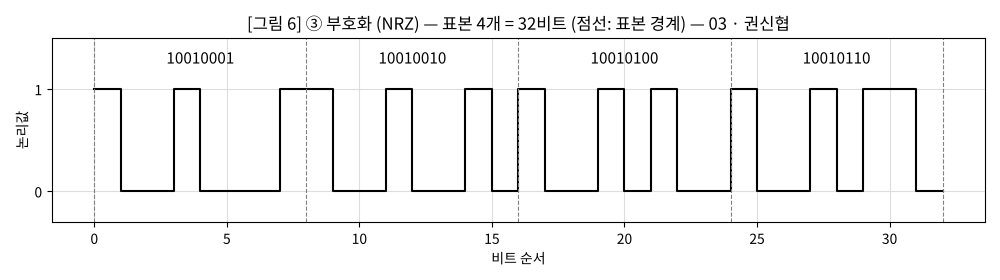

In [ ]:
# ===== 5-5. [그림 6] ③ 부호화 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 양자화 레벨 번호를 n 비트 2진 부호로 변환
#   2) 부호화 표 (표본 번호 · 표본값 · 레벨 · 2진 부호) 일부 출력
#   3) 부호화된 펄스열(NRZ) 그래프
#   4) 그래프 제목에 '[그림 6]'과 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
codes = [format(i, f"0{n_bits}b") for i in q_idx]                                  # 레벨 번호 → 자연 2진 부호
bits = ((q_idx[:, None] >> np.arange(n_bits - 1, -1, -1)) & 1).astype(np.uint8).ravel()   # 전체 비트열

print(f"{'표본 번호':>8} {'표본값':>9} {'레벨':>5}  2진 부호")
for k in range(k0, k0 + 8):
    print(f"{k + 1:>8} {x_s[k]:>9.4f} {q_idx[k]:>5d}  {codes[k]}")
print(f"\n비트율 = {fs_pcm:,} Hz × {n_bits} bit = {fs_pcm * n_bits:,} bps")
print(f"전체 비트 수 = {len(bits):,} bit ({len(bits) / 8 / 1024:.1f} KB)")

n_show = 4
seg = bits[k0 * n_bits:(k0 + n_show) * n_bits]
tb = np.arange(len(seg) + 1)
plt.figure(figsize=(10, 2.8))
plt.step(tb, np.append(seg, seg[-1]), where="post", lw=1.5)
for j in range(n_show + 1):
    plt.axvline(j * n_bits, color="gray", ls="--", lw=0.8)
for j in range(n_show):
    plt.text(j * n_bits + n_bits / 2, 1.25, codes[k0 + j], ha="center", fontsize=11)
plt.ylim(-0.3, 1.5); plt.yticks([0, 1])
plt.title(f"[그림 6] ③ 부호화 (NRZ) — 표본 {n_show}개 = {n_show * n_bits}비트 (점선: 표본 경계) — 03 · 권신협")
plt.xlabel("비트 순서"); plt.ylabel("논리값")
plt.tight_layout()
plt.show()

In [ ]:
# ===== 5-6. 부호화 일련 데이터 출력 (앞부분부터) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 표시 범위대로, 부호화 데이터의 앞부분부터 연속된 비트열 출력
#   2) 표본 단위로 띄어 쓴 형태와 연속 비트열 형태 모두
#   3) 출력한 표본 수와 비트 수
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
show = codes[SHOW_START - 1:SHOW_START - 1 + SHOW_N]
print("표본 단위로 띄어 쓴 형태:")
print(" ".join(show))
print()
print("연속 비트열 형태:")
print("".join(show))
print()
print(f"출력한 표본 수: {len(show)}개, 비트 수: {len(''.join(show))}비트 ({len(show)} × {n_bits})")
print(f"전체: 표본 {len(codes):,}개, 비트 {len(codes) * n_bits:,}비트")

표본 단위로 띄어 쓴 형태:
10000110 10000110 10000100 10000001 10000000 10000010 10000011 10000011 10000001 10000001 10000001 10000001 10000000 01111110 01111100 01111100

연속 비트열 형태:
10000110100001101000010010000001100000001000001010000011100000111000000110000001100000011000000110000000011111100111110001111100

출력한 표본 수: 16개, 비트 수: 128비트 (16 × 8)
전체: 표본 30,686개, 비트 245,488비트


### 5-7. PCM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| 표본화 주파수 / 표본 수 | 8000 Hz / 약 30,686개 (3.84초 × 8000) | 8000 Hz / 30,686개 | 일치합니다. 원 신호 169,156개가 약 5.5배 줄었습니다. |
| 양자화 레벨 수 L | 256 | 256 | 일치합니다. 레벨 번호는 0 ~ 255이고 최대 양자화 오차는 Δ/2 = 0.0039였습니다. |
| SQNR | 이론 49.92 dB | 측정 32.88 dB | 측정값이 약 17 dB 낮습니다. 이론식은 −1 ~ +1 V를 가득 채우는 사인파를 기준으로 합니다. 이번 음성은 93 %의 표본에서 \|x\| < 0.2이고 신호 전력이 약 0.0106(실효값 0.103)으로 작아 SQNR이 낮아졌습니다. 양자화 오차 전력은 Δ²/12와 거의 같았습니다. |
| 비트율 / 전체 비트 수 | 64,000 bps / 30,686 × 8 = 245,488비트 | 64,000 bps / 245,488비트 | 일치합니다. |

**부호화 일련 데이터 (5-6 출력 붙여넣기)**
```
표본 단위로 띄어 쓴 형태:
10000110 10000110 10000100 10000001 10000000 10000010 10000011 10000011 10000001 10000001 10000001 10000001 10000000 01111110 01111100 01111100

연속 비트열 형태:
10000110100001101000010010000001100000001000001010000011100000111000000110000001100000011000000110000000011111100111110001111100

출력한 표본 수: 16개, 비트 수: 128비트 (16 × 8)
```


---
## ✅ 제출 전 체크리스트
- [ ] 번호, 이름을 작성했다
- [ ] 내 목소리를 입력했고 재생된다.
- [ ] **설계표를 코드 작성 전에** 작성했고, 선언한 변수값과 일치한다
- [ ] [그림 1] ~ [그림 6] 그래프가 모두 출력되어 있고 제목에 번호 · 이름이 있다
- [ ] 부호화 일련 데이터(앞부분)가 출력되어 있다
- [ ] 결과 기록표와 고찰을 모두 작성했다
- [ ] **런타임 → 모두 실행** 후 오류 없이 저장했다